### Tasks. Part 1. Unsupervised Learning: Dimensionality Reduction on Digits

We'd like to visualize our points within the 64-dimensional parameter space, but it's difficult to plot points in $N=64$ dimensions! So we need to reduce the dimensionality of the space


3) Use the unsupervised dimensionality reduction technique called **[`Isomap`](http://scikit-learn.org/stable/modules/generated/sklearn.manifold.Isomap.html#sklearn.manifold.Isomap)**. Isomap is an embedding tecnique, which tries to understand if your $N$ dimensional datapoint live in a $M$ dimensional (with $M<N$) manyfold. Reduce the MINST dataset.  Do some plots to visualize your results 

*Note*. Isomap is very recent. It was introduced by [Tenenbaum et al (2000)](https://www.science.org/doi/10.1126/science.290.5500.2319) ---a paper that has something like $1.5\times 10^4$ [citations](https://scholar.google.com/scholar?hl=en&as_sdt=0%2C5&q=a+global+geometric+framework+for+nonlinear+dimensionality+reduction&btnG=).

### Tasks. Part 2. Supervised Learning: Classification on Digits

Now we want to classify the dataset. 

4) Split the dataset taking 80% of the images as tranining dataset and leaving the other 20% as a validation set. You need `sklearn.model_selection.train_test_split`.

5) Use a simple [`Logistic Regression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) which despite its name is a common classification algorithm. (I know, this is confusing!). Use the flag `solver='sag'` (I found the default solver had a bug, at least when I tried).

6) Compute the accuracy (`sklearn.metrics.accuracy_score`) of your emulator. In this context, accuracy is simply the fraction of the digits that were correctly identified. Compute the accuracy on both the training and the validation set. Comment on the results.

7) The accuracy is a single number doesn't tell us ***where*** we've gone wrong. Plot the ***confusion matrix*** as we did above. What are the digits that are more challenging to identify, does it make sense?


There are many ways to improve this classifier, for example using a more sophisticated model, use cross validation, etc.  We'll get to those in the coming weeks.

In [1]:
from sklearn import datasets
from sklearn.manifold import Isomap 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as LR
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from matplotlib import pyplot as plt
import numpy as np

In [2]:
digits = datasets.load_digits()
print(digits.images.shape)
print(digits.keys())
labels = digits.target

(1797, 8, 8)
dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])


In [3]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

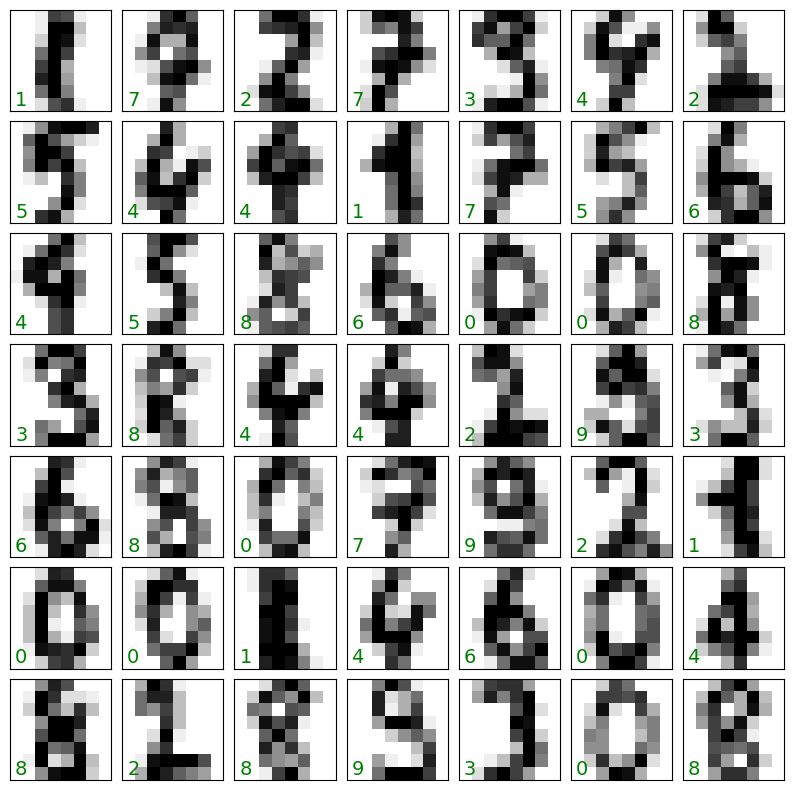

In [4]:
fig, axes = plt.subplots(7,7, figsize=(10, 10))
fig.subplots_adjust(hspace=0.1, wspace=0.1)

np.random.seed(42)
mychoices = np.random.choice(digits.images.shape[0],100)

for i, ax in enumerate(axes.flat):
    ax.imshow((digits.images[mychoices[i]]), 
              cmap='binary')
    ax.text(0.05, 0.05, str(digits.target[mychoices[i]]),transform=ax.transAxes, color='green', fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])
    

In [5]:
print(digits.images[1, :, :])

[[ 0.  0.  0. 12. 13.  5.  0.  0.]
 [ 0.  0.  0. 11. 16.  9.  0.  0.]
 [ 0.  0.  3. 15. 16.  6.  0.  0.]
 [ 0.  7. 15. 16. 16.  2.  0.  0.]
 [ 0.  0.  1. 16. 16.  3.  0.  0.]
 [ 0.  0.  1. 16. 16.  6.  0.  0.]
 [ 0.  0.  1. 16. 16.  6.  0.  0.]
 [ 0.  0.  0. 11. 16. 10.  0.  0.]]


### Task 1

In [6]:
embedding = Isomap(n_components=4)
new_images = embedding.fit_transform(digits.data)
new_images.shape

C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anaconda3\Lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


(1797, 4)

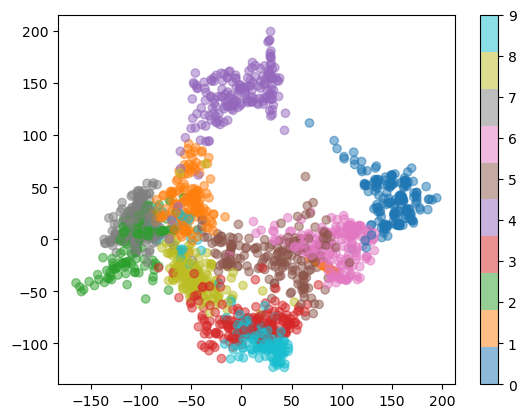

In [7]:
plt.scatter(new_images[:, 0], new_images[:, 1], c = digits.target, cmap = 'tab10', alpha = 0.5)
plt.colorbar()
plt.show()

### Task 2

In [8]:
X_train, X_test, y_train, y_test = train_test_split(new_images, labels, test_size=0.20, random_state=42)

In [9]:
method = LR(solver='sag')
method.fit(X_train, y_train)

C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(solver='sag')

In [10]:
y_pred_t = method.predict(X_train)
y_pred = method.predict(X_test)

In [11]:
print(confusion_matrix(y_train, y_pred_t))
print(confusion_matrix(y_test, y_pred))
print(accuracy_score(y_train, y_pred_t))
print(accuracy_score(y_test, y_pred))

[[145   0   0   0   0   0   0   0   0   0]
 [  0 136   8   0   0   0   9   0   1   0]
 [  0   4 136   1   0   0   0   0   3   0]
 [  0   0   0 128   0   1   0   1   4  15]
 [  0   0   0   0 133   1   0   0   0   1]
 [  0   1   0   0   1 131   0   0   0   2]
 [  0  11   0   0   0   0 135   0   0   0]
 [  0   0   0   0   0   1   0 141   0   3]
 [  0   4  11   4   0   0   0   1 121   3]
 [  0   0   1  16   0   1   0  20   1 101]]
[[33  0  0  0  0  0  0  0  0  0]
 [ 0 25  2  0  0  0  1  0  0  0]
 [ 0  1 30  0  0  0  0  0  2  0]
 [ 0  0  0 29  0  0  0  0  2  3]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  1  0  0  0 44  1  0  0  1]
 [ 0  1  0  0  0  1 33  0  0  0]
 [ 0  0  0  0  0  0  0 34  0  0]
 [ 0  1  3  0  0  0  0  0 26  0]
 [ 0  0  0  3  2  2  0  3  0 30]]
0.9095337508698678
0.9166666666666666


In [12]:
for i in range(2, 10):
    embedding = Isomap(n_components=i)
    new_images = embedding.fit_transform(digits.data)
    X_train, X_test, y_train, y_test = train_test_split(new_images, labels, test_size=0.20, random_state=42)
    method = LR(solver='sag')
    method.fit(X_train, y_train)
    y_pred = method.predict(X_test)
    print(confusion_matrix(y_test, y_pred))
    print(accuracy_score(y_test, y_pred))

C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anaconda3\Lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anac

[[33  0  0  0  0  0  0  0  0  0]
 [ 0 13  0  0  3  0  5  7  0  0]
 [ 0  1 14  0  0  0  0 15  3  0]
 [ 0  0  0 27  0  0  0  0  3  4]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 3  3  2  3  0 21  9  1  5  0]
 [ 8  0  0  0  0  1 26  0  0  0]
 [ 0  0 10  0  0  0  0 24  0  0]
 [ 0  0  4  1  0  0  0  0 23  2]
 [ 0  0  1 33  0  0  0  6  0  0]]
0.6305555555555555


C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anaconda3\Lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


[[33  0  0  0  0  0  0  0  0  0]
 [ 0 20  3  0  0  0  5  0  0  0]
 [ 0  1 30  0  0  0  0  0  2  0]
 [ 0  0  0 30  0  1  0  0  0  3]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 5 10  1  3  0 23  2  0  3  0]
 [ 0  1  0  0  0  3 31  0  0  0]
 [ 0  0  1  0  0  0  0 33  0  0]
 [ 0  0  2  0  0  0  0  0 27  1]
 [ 0  0  1  8  0  0  0  6  0 25]]
0.8277777777777777
[[33  0  0  0  0  0  0  0  0  0]
 [ 0 25  2  0  0  0  1  0  0  0]
 [ 0  1 30  0  0  0  0  0  2  0]
 [ 0  0  0 29  0  0  0  0  2  3]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  1  0  0  0 44  1  0  0  1]
 [ 0  1  0  0  0  1 33  0  0  0]
 [ 0  0  0  0  0  0  0 34  0  0]
 [ 0  1  3  0  0  0  0  0 26  0]
 [ 0  0  0  3  2  2  0  3  0 30]]
0.9166666666666666


C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anaconda3\Lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anac

...

C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anaconda3\Lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


[[33  0  0  0  0  0  0  0  0  0]
 [ 0 27  1  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  0  0  0  0  1]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  0  0  0  0  0  0  0 30  0]
 [ 0  0  0  0  1  0  0  0  0 39]]
0.9861111111111112


C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:384: UserWarning: The number of connected components of the neighbors graph is 2 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\nicco\anaconda3\Lib\site-packages\scipy\sparse\_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


[[33  0  0  0  0  0  0  0  0  0]
 [ 0 27  1  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  0  0  0  0  1]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  0  0  0  0  0  0  0 30  0]
 [ 0  0  0  0  1  0  0  0  0 39]]
0.9861111111111112
[[33  0  0  0  0  0  0  0  0  0]
 [ 0 27  1  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 46  1  0  0  0]
 [ 0  0  0  0  0  1 34  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  0  0  0  0  0  0  0 30  0]
 [ 0  0  0  0  1  0  0  0  0 39]]
0.9833333333333333


C:\Users\nicco\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
